# ⚡ EVCharge Intelligence Analytics

### EV Charging Usage & Energy Consumption Analysis

**Tools:** Python, Pandas, SQL, Power BI

**Dataset:** EV Charging Transactions

## 🎯 Project Objectives

- Analyze EV Charging Transactions.
- Calculate Total Energy Consumption.
- Identify Peak Charging Hours.
- Analyze Charging Duration.
- Compare Charging Point Usage.
- Create An Interactive Power BI Dashboard.


### 1. Import Libraries

In [ ]:
import pandas as pd

### 2. Load Dataset

In [ ]:
df = pd.read_csv('/content/Charge Transactions.csv', sep=',')
df.head()

,Charging Point Number,Transaction Start,Charge Start,Charge End,Transaction End,Start Wh,End Wh,Total Wh,Connect Time
0,6118,01/01/2020 02:04:13,01/01/2020 02:04:14,01/01/2020 09:42:50,01/01/2020 09:46:41,103497.0,126990.0,23493.0,462.0
1,6132,01/01/2020 13:40:41,01/01/2020 13:40:42,01/01/2020 14:24:48,01/01/2020 14:24:50,22619.0,25094.0,2475.0,44.0
2,6184,01/01/2020 16:37:09,01/01/2020 16:37:10,01/01/2020 16:50:23,01/01/2020 16:50:28,3373.0,4063.0,690.0,13.0
3,6132,01/01/2020 22:45:53,01/01/2020 22:45:54,02/01/2020 02:11:46,02/01/2020 02:11:59,25139.0,37557.0,12418.0,206.0
4,6132,02/01/2020 12:17:40,02/01/2020 12:17:41,02/01/2020 15:00:28,02/01/2020 15:00:28,37607.0,47385.0,9778.0,162.0


### 3. Dataset Overview

In This Section, We Will Understand The Dataset Structure, Columns, Data Types And Number of Records.

In [ ]:
df.shape

(2415, 9)

In [ ]:
df.columns

Index(['Charging Point Number', 'Transaction Start', 'Charge Start',
       'Charge End', 'Transaction End', 'Start Wh', 'End Wh', 'Total Wh',
       'Connect Time'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2415 entries, 0 to 2414
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Charging Point Number  2415 non-null   int64  
 1   Transaction Start      2415 non-null   object 
 2   Charge Start           2414 non-null   object 
 3   Charge End             2414 non-null   object 
 4   Transaction End        2414 non-null   object 
 5   Start Wh               2414 non-null   float64
 6   End Wh                 2414 non-null   float64
 7   Total Wh               2414 non-null   float64
 8   Connect Time           2414 non-null   float64
dtypes: float64(4), int64(1), object(4)
memory usage: 169.9+ KB


In [ ]:
df.isnull().sum()

,0
Charging Point Number,0
Transaction Start,0
Charge Start,1
Charge End,1
Transaction End,1
Start Wh,1
End Wh,1
Total Wh,1
Connect Time,1


In [ ]:
df.duplicated().sum()

np.int64(180)

In [ ]:
df[df.isnull().any(axis=1)]

,Charging Point Number,Transaction Start,Charge Start,Charge End,Transaction End,Start Wh,End Wh,Total Wh,Connect Time
2413,6151,15/06/2021 10:24:23,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 4. Data Cleaning

In this Section, We Will Remove Duplicate Records, Handle Missing Values And Prepare The Dataset For Analysis.


In [ ]:
df = df.drop_duplicates()

df.shape

(2235, 9)

In [ ]:
df.isnull().sum()

,0
Charging Point Number,0
Transaction Start,0
Charge Start,1
Charge End,1
Transaction End,1
Start Wh,1
End Wh,1
Total Wh,1
Connect Time,1


In [ ]:
df = df.dropna()

df.shape

(2234, 9)

In [ ]:
df.isnull().sum().sum(), df.duplicated().sum()

(np.int64(0), np.int64(0))

In [ ]:
date_columns = ['Transaction Start', 'Charge Start', 'Charge End', 'Transaction End']

for col in date_columns:
    df[col] = pd.to_datetime(df[col], dayfirst=True, errors='coerce')

df[date_columns].dtypes

,0
Transaction Start,datetime64[ns]
Charge Start,datetime64[ns]
Charge End,datetime64[ns]
Transaction End,datetime64[ns]


In [ ]:
energy_columns = ['Start Wh', 'End Wh', 'Total Wh']

for col in energy_columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

df[energy_columns].dtypes

,0
Start Wh,float64
End Wh,float64
Total Wh,float64


In [ ]:
df[energy_columns].head()

,Start Wh,End Wh,Total Wh
0,103497.0,126990.0,23493.0
1,22619.0,25094.0,2475.0
2,3373.0,4063.0,690.0
3,25139.0,37557.0,12418.0
4,37607.0,47385.0,9778.0


In [ ]:
df['Energy_kWh'] = df['Total Wh'] / 1000

df[['Total Wh', 'Energy_kWh']].head()

,Total Wh,Energy_kWh
0,23493.0,23.493
1,2475.0,2.475
2,690.0,0.690
3,12418.0,12.418
4,9778.0,9.778


In [ ]:
df['Charging_Duration_Min'] = (
    df['Charge End'] - df['Charge Start']
).dt.total_seconds() / 60

df[['Charge Start', 'Charge End', 'Charging_Duration_Min']].head()

,Charge Start,Charge End,Charging_Duration_Min
0,2020-01-01 02:04:14,2020-01-01 09:42:50,458.600000
1,2020-01-01 13:40:42,2020-01-01 14:24:48,44.100000
2,2020-01-01 16:37:10,2020-01-01 16:50:23,13.216667
3,2020-01-01 22:45:54,2020-01-02 02:11:46,205.866667
4,2020-01-02 12:17:41,2020-01-02 15:00:28,162.783333


In [ ]:
df['Charging_Duration_Min'].describe()

,Charging_Duration_Min
count,2234.000000
mean,309.127320
std,276.276779
min,0.000000
25%,123.979167
50%,215.208333
75%,430.787500
max,1698.300000


In [ ]:
(df['Charging_Duration_Min'] <= 0).sum()

np.int64(41)

In [ ]:
df[df['Charging_Duration_Min'] <= 0]

,Charging Point Number,Transaction Start,Charge Start,Charge End,Transaction End,Start Wh,End Wh,Total Wh,Connect Time,Energy_kWh,Charging_Duration_Min
259,6120,2020-06-24 14:11:35,2020-06-24 14:11:35,2020-06-24 14:11:35,2020-06-24 14:13:29,130710.0,130711.0,1.0,1.0,0.001,0.0
260,6120,2020-06-24 14:13:54,2020-06-24 14:13:54,2020-06-24 14:13:54,2020-06-24 14:16:46,130711.0,130711.0,0.0,2.0,0.000,0.0
368,6171,2020-08-08 12:12:53,2020-08-08 12:12:53,2020-08-08 12:12:53,2020-08-08 12:13:14,283562897.0,283562897.0,0.0,0.0,0.000,0.0
383,6118,2020-08-15 08:27:30,2020-08-15 08:27:30,2020-08-15 08:27:30,2020-08-15 08:27:44,705016.0,705016.0,0.0,0.0,0.000,0.0
384,6118,2020-08-15 08:28:05,2020-08-15 08:28:05,2020-08-15 08:28:05,2020-08-15 08:28:59,705016.0,705017.0,1.0,0.0,0.001,0.0
403,6197,2020-08-24 17:14:30,2020-08-24 17:14:30,2020-08-24 17:14:30,2020-08-24 17:18:10,1.0,1.0,0.0,3.0,0.000,0.0
440,6136,2020-09-06 09:53:31,2020-09-06 09:53:31,2020-09-06 09:53:31,2020-09-06 09:53:56,462082.0,462082.0,0.0,0.0,0.000,0.0
456,6132,2020-09-10 22:00:46,2020-09-10 22:00:46,2020-09-10 22:00:46,2020-09-11 07:09:49,1027712.0,1027761.0,49.0,549.0,0.049,0.0
467,6132,2020-09-13 20:35:07,2020-09-13 20:35:07,2020-09-13 20:35:07,2020-09-13 20:36:34,1065577.0,1065577.0,0.0,1.0,0.000,0.0
468,6132,2020-09-13 20:36:51,2020-09-13 20:36:51,2020-09-13 20:36:51,2020-09-13 20:38:10,1065577.0,1065577.0,0.0,1.0,0.000,0.0


In [ ]:
df.loc[df['Charging_Duration_Min'] <= 0, ['Energy_kWh', 'Charging_Duration_Min']].describe()

,Energy_kWh,Charging_Duration_Min
count,41.000000,41.0
mean,0.055951,0.0
std,0.332407,0.0
min,0.000000,0.0
25%,0.000000,0.0
50%,0.000000,0.0
75%,0.000000,0.0
max,2.131000,0.0


In [ ]:
(df.loc[df['Charging_Duration_Min'] <= 0, 'Energy_kWh'] > 0).sum()

np.int64(10)

In [ ]:
df = df[df['Charging_Duration_Min'] > 0].copy()

df.shape

(2193, 11)

In [ ]:
print("Dataset Shape:", df.shape)
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())
print("Invalid Durations:", (df['Charging_Duration_Min'] <= 0).sum())

Dataset Shape: (2193, 11)
Missing Values: 0
Duplicate Rows: 0
Invalid Durations: 0


### ✅ Data Cleaning Summary

- Removed Duplicate Records.
- Removed Records With Missing Values.
- Converted Transaction Columns to Datetime Format.
- Converted Energy columns To Numeric Format.
- Created `Energy_kWh` to Measure energy consumption In Kilowatt-Hours.
- Created `Charging_Duration_Min` To Calculate Charging Duration.
- Removed Records With Zero Or Negative Charging Duration.


### 5. Exploratory Data Analysis (EDA)

In This Section, We Will Analyze EV Charging Transactions, Energy Consumption, Charging Duration And Charging Point Usage To Discover Meaningful Patterns And Insights.


In [ ]:
df[['Energy_kWh', 'Charging_Duration_Min']].describe().round(2)

,Energy_kWh,Charging_Duration_Min
count,2193.00,2193.00
mean,14.65,314.91
std,13.10,275.56
min,0.00,0.02
25%,6.07,126.88
50%,10.41,219.45
75%,21.04,436.52
max,99.11,1698.30


#### Peak Charging Hours

Analyze Charging Session Start Times To Identify The Busiest Hours And Understand EV Charging Usage Patterns.


In [ ]:
df['Charging_Hour'] = df['Charge Start'].dt.hour

hourly_sessions = df['Charging_Hour'].value_counts().sort_index()

hourly_sessions

,count
Charging_Hour,
0,8
1,2
2,4
3,3
5,3
6,20
7,66
8,114
9,141


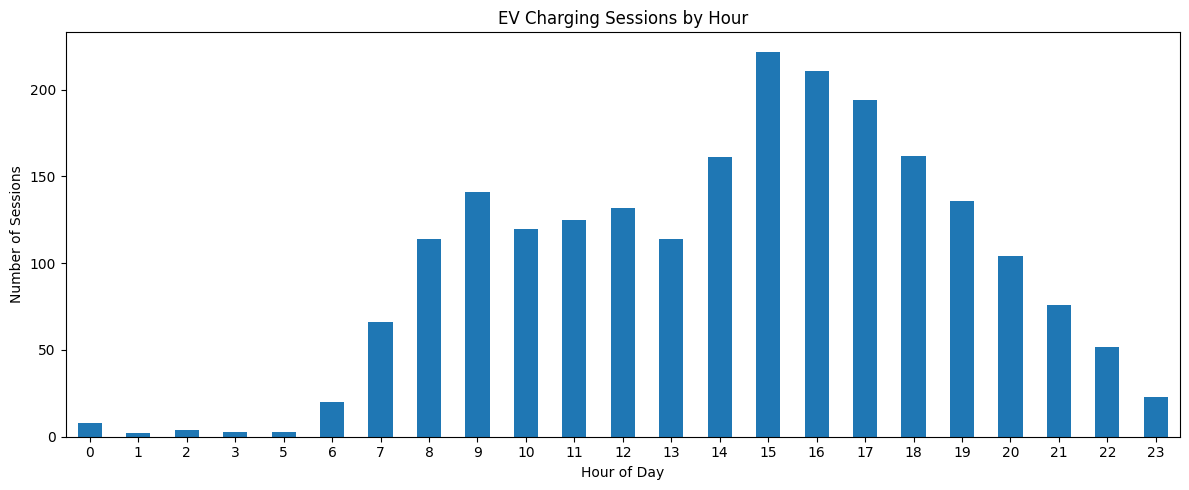

In [ ]:
import matplotlib.pyplot as plt

hourly_sessions.plot(kind='bar', figsize=(12, 5))

plt.title('EV Charging Sessions by Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Sessions')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#### Monthly Energy Consumption Analysis

Analyze Monthly Energy Consumption To Identify Changes In EV Charging Demand Over Time.


In [ ]:
df['Month'] = df['Charge Start'].dt.to_period('M')

monthly_energy = df.groupby('Month')['Energy_kWh'].sum()

monthly_energy.round(2)

,Energy_kWh
Month,
2020-01,618.66
2020-02,547.02
2020-03,626.02
2020-04,302.34
2020-05,336.67
2020-06,472.78
2020-07,568.89
2020-08,660.80
2020-09,1457.20


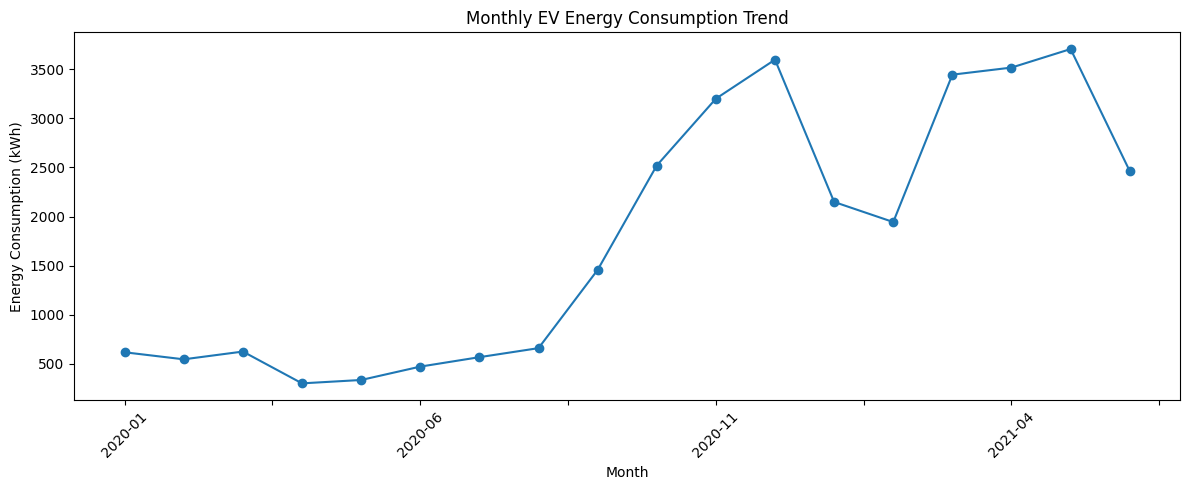

In [ ]:
monthly_energy.index = monthly_energy.index.astype(str)

monthly_energy.plot(
    kind='line',
    marker='o',
    figsize=(12, 5)
)

plt.title('Monthly EV Energy Consumption Trend')
plt.xlabel('Month')
plt.ylabel('Energy Consumption (kWh)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Charging Point Usage Analysis

Analyze Charging Sessions Across Different Charging Points To Identify The Most Frequently Used Charging Locations.


In [ ]:
charging_point_usage = df['Charging Point Number'].value_counts()

charging_point_usage.head(10)

,count
Charging Point Number,
6118,238
6132,217
6189,189
6136,143
6143,106
6193,63
6155,62
6175,62
6151,59


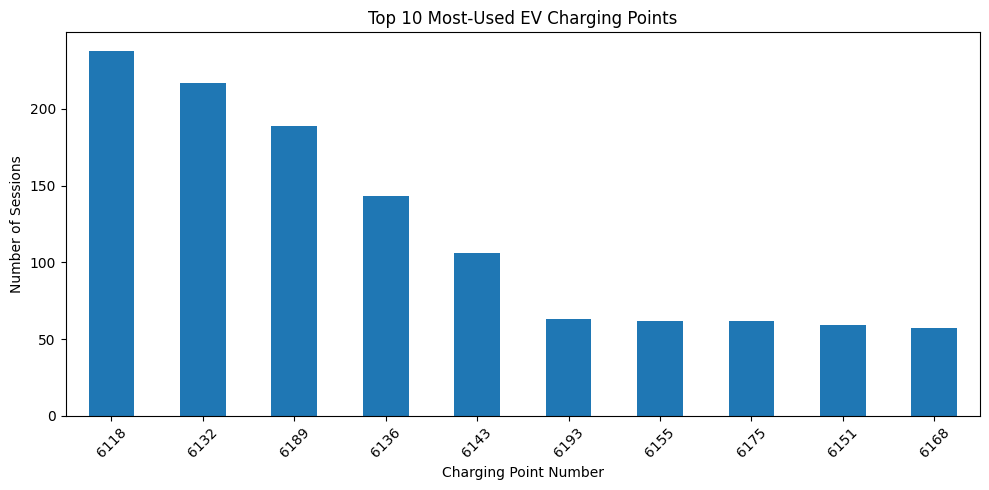

In [ ]:
charging_point_usage.head(10).plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Top 10 Most-Used EV Charging Points')
plt.xlabel('Charging Point Number')
plt.ylabel('Number of Sessions')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Energy Consumption by Charging Point

Compare Total Energy Consumption Across Charging Points To Identify The Points With The Highest Energy Demand.


In [ ]:
energy_by_point = (
    df.groupby('Charging Point Number')['Energy_kWh']
    .sum()
    .sort_values(ascending=False)
)

energy_by_point.head(10).round(2)

,Energy_kWh
Charging Point Number,
6189,4074.52
6132,3879.69
6118,2778.96
6136,2251.36
6151,1895.06
6143,1272.58
6184,1181.62
6119,917.27
6168,900.71


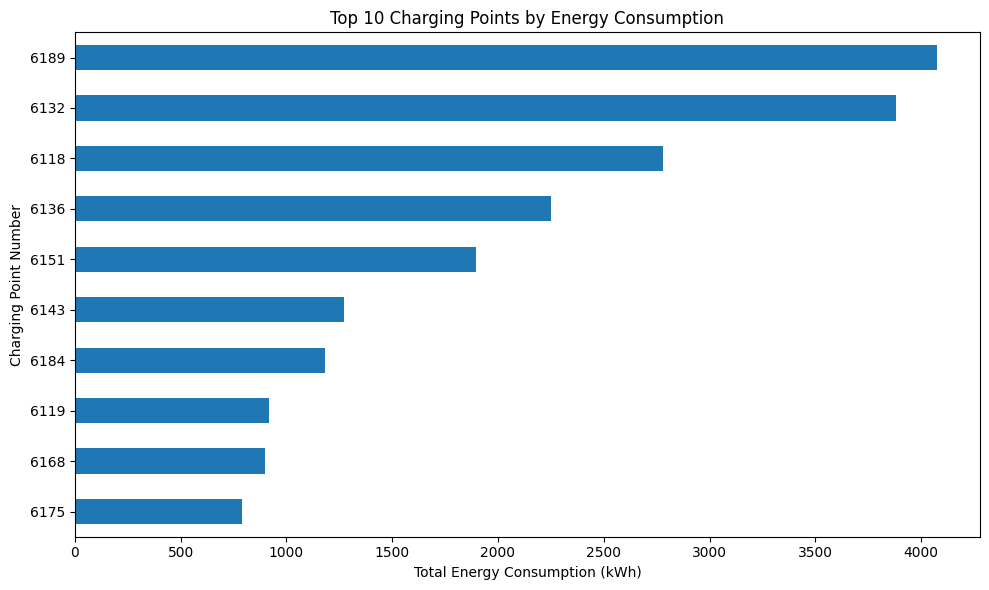

In [ ]:
energy_by_point.head(10).sort_values().plot(
    kind='barh',
    figsize=(10, 6)
)

plt.title('Top 10 Charging Points by Energy Consumption')
plt.xlabel('Total Energy Consumption (kWh)')
plt.ylabel('Charging Point Number')
plt.tight_layout()
plt.show()

#### Charging Duration Analysis

Analyze Charging Session Durations to Understand Typical Session Lengths And Identify Unusually Long Charging Sessions.


In [ ]:
df['Charging_Duration_Min'].describe().round(2)

,Charging_Duration_Min
count,2193.00
mean,314.91
std,275.56
min,0.02
25%,126.88
50%,219.45
75%,436.52
max,1698.30


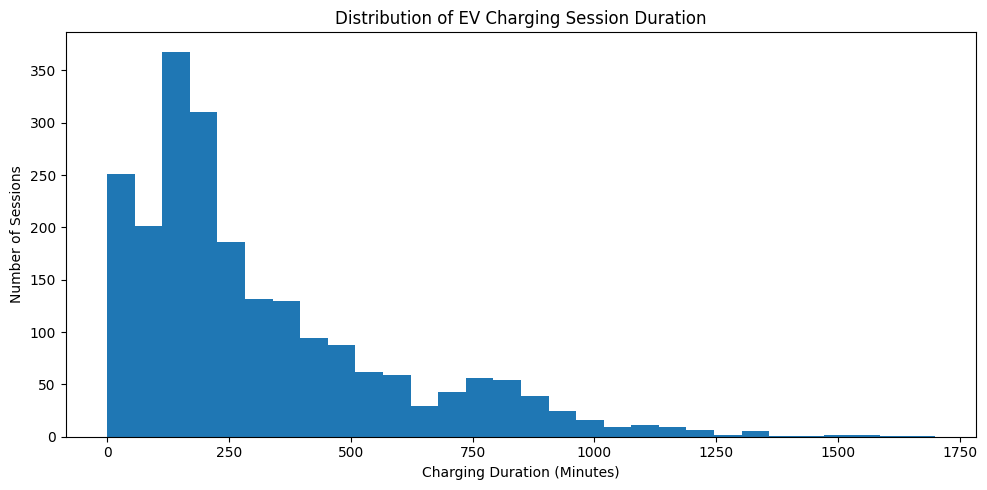

In [ ]:
df['Charging_Duration_Min'].plot(
    kind='hist',
    bins=30,
    figsize=(10, 5)
)

plt.title('Distribution of EV Charging Session Duration')
plt.xlabel('Charging Duration (Minutes)')
plt.ylabel('Number of Sessions')
plt.tight_layout()
plt.show()

#### Energy Consumption vs Charging Duration

Analyze the Relationship Between Charging Duration And Energy Consumption To Understand How Session Length Relates To The Amount Of Energy Delivered.


In [ ]:
df[['Energy_kWh', 'Charging_Duration_Min']].corr().round(2)

,Energy_kWh,Charging_Duration_Min
Energy_kWh,1.00,0.82
Charging_Duration_Min,0.82,1.00


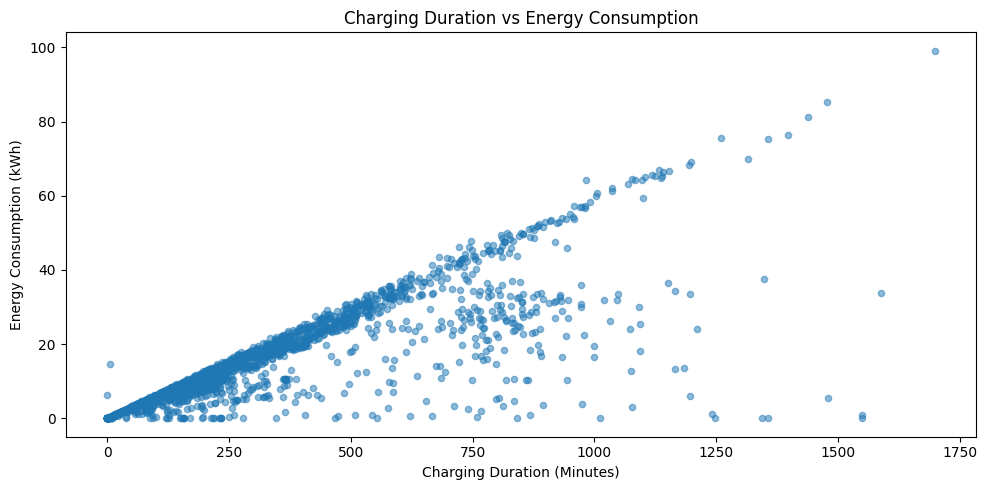

In [ ]:
df.plot(
    kind='scatter',
    x='Charging_Duration_Min',
    y='Energy_kWh',
    figsize=(10, 5),
    alpha=0.5
)

plt.title('Charging Duration vs Energy Consumption')
plt.xlabel('Charging Duration (Minutes)')
plt.ylabel('Energy Consumption (kWh)')
plt.tight_layout()
plt.show()

## 6. Key Findings & Business Insights

### 📊 1. Energy Consumption

* Average Energy Consumption Per Charging Session is **14.65 kWh**.
* The Highest Monthly Energy Consumption was **3,705.09 kWh in May 2021**.

### ⏰ 2. Peak Charging Hours

* **3 PM** Recorded The Highest Number Of Charging Session Starts, With **222 Sessions**.
* Charging Activity Was Also High Between 4 PM and 6 PM.

### 🔌 3. Charging Point Usage

* Charging Point **6118** Recorded The Highest Number Of Sessions, with **238 sessions**.
* Charging Point **6189** Recorded The Highest Total Energy Consumption At **4,074.52 kWh**.

### ⏱️ 4. Charging Duration

* Average Charging Duration Was Approximately **5 hours 15 minutes**.
* The Longest Recorded Session Lasted Approximately **28 hours 18 minutes**.

### 🔗 5. Energy And Duration Relationship

* Energy Consumption And Charging Duration Had a Correlation Of **0.82** Indicating a Strong Positive Linear Relationship.

### 💡 Business Recommendations

* Monitor Peak-Hour Demand to Improve Charging Point Availability.
* Review charging Points With High Energy Consumption for Capacity Planning.
* Investigate Unusually Long Sessions To Identify Possible Operational Issues.
* Use Energy Consumption And Session Duration Metrics to Support Charging Infrastructure Planning.


### 7. Export Cleaned Dataset

Export The Cleaned And Analyzed EV charging Transaction Data To a CSV File For SQL Analysis and Power BI Dashboard Development.


In [ ]:
df.to_csv('EV_Charging_Cleaned.csv', index=False)

print("Cleaned dataset exported successfully!")
print("Dataset shape:", df.shape)

Cleaned dataset exported successfully!
Dataset shape: (2193, 13)


In [ ]:
from google.colab import files

files.download('EV_Charging_Cleaned.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Outlier check: sessions longer than 12 hours (720 min)
total = len(df)
outliers = (df['Charging_Duration_Min'] > 720).sum()
print("Total sessions:", total)
print("Outliers (>720 min):", outliers)
print("Percentage:", round(outliers / total * 100, 1), "%")

# Optional: filtered version save karo
df_final = df[df['Charging_Duration_Min'] <= 720]
print("Rows after filter:", len(df_final))
df_final.to_csv("ev_charging_final.csv", index=False)

Total sessions: 2193
Outliers (>720 min): 260
Percentage: 11.9 %
Rows after filter: 1933
